# Final Deep RL vs MPC Comparison

Evaluation-only notebook. It loads the final PPO policy, reconstructs the final tuned MPC policy, generates four fixed unseen DreamGym roads, evaluates both policies on the same roads and reset seeds, computes the same client metrics, and animates both policies on every road.

No retraining and no retuning are performed here.

In [27]:
from pathlib import Path
import copy
import json

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

from dreamgym.envs import Road
from dreamgym.envs.road_core import (
    generate_random_road_spec,
    normalize_random_road_generation_config,
)

from dreamgym.evaluation import MetricSet, PerformanceMetric
from dreamgym.evaluation.autonomous_driving import (
    metric_by_name,
    simulate_policy,
    simulate_mpc_policy,
)

from dreamgym.policies.autonomous_driving import (
    RLPolicy,
    AutonomousDrivingSteeringRateMPCPolicy,
    AutonomousDrivingSteeringRateMPCConfig,
    KinematicBicycleMPCModelConfig,
    SteeringRateMPCObjectiveConfig,
    SteeringRateMPCConstraintConfig,
    MPCFallbackConfig,
    MPCFallbackMode,
)
from dreamgym.policies.mpc import MPCSolverConfig
from dreamgym.training.autonomous_driving import load_model_and_config_for_evaluation

FINAL_RL_MODEL_PATH = Path(
    "notebook_outputs/rl-reward-shaping-and-training/combined/"
    "rl-reward-shaping-combined_20260901-151651/models/final.zip"
)
FINAL_RL_CONFIG_PATH = Path(
    "notebook_outputs/rl-reward-shaping-and-training/combined/"
    "rl-reward-shaping-combined_20260901-151651/resolved_config.json"
)

N_STEPS = 5000
BASE_RESET_SEED = 20261210
DT = 0.05

OUTPUT_ROOT = Path("notebook_outputs") / "final-rl-vs-mpc-comparison"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not FINAL_RL_MODEL_PATH.is_file():
    raise FileNotFoundError(FINAL_RL_MODEL_PATH)
if not FINAL_RL_CONFIG_PATH.is_file():
    raise FileNotFoundError(FINAL_RL_CONFIG_PATH)

print("RL model:", FINAL_RL_MODEL_PATH)
print("RL config:", FINAL_RL_CONFIG_PATH)
print("Output:", OUTPUT_ROOT)

RL model: notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260901-151651/models/final.zip
RL config: notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260901-151651/resolved_config.json
Output: notebook_outputs/final-rl-vs-mpc-comparison


## 1. Load the common client metrics

In [28]:
PERFORMANCE_METRICS_NOTEBOOK_PATH = Path(
    "ad_gym_performance_metrics_and_uncertainty_2026_08_17.ipynb"
)

if not PERFORMANCE_METRICS_NOTEBOOK_PATH.is_file():
    raise FileNotFoundError(PERFORMANCE_METRICS_NOTEBOOK_PATH)

with PERFORMANCE_METRICS_NOTEBOOK_PATH.open("r", encoding="utf-8") as f:
    performance_notebook = json.load(f)

metric_definition_code_cells = []
inside_metric_section = False

for cell in performance_notebook["cells"]:
    source = "".join(cell.get("source", ())).strip()

    if cell["cell_type"] == "markdown":
        if source.startswith("## 1. Define the metrics"):
            inside_metric_section = True
            continue
        if inside_metric_section and source.startswith(
            "### Simulate a roll-out and compute the metrics"
        ):
            break
    elif inside_metric_section and cell["cell_type"] == "code":
        metric_definition_code_cells.append(source)

if not metric_definition_code_cells:
    raise RuntimeError("Could not find metric definitions.")

metric_namespace = {
    "__builtins__": __builtins__,
    "np": np,
    "MetricSet": MetricSet,
    "PerformanceMetric": PerformanceMetric,
    "metric_by_name": metric_by_name,
}

for code_cell in metric_definition_code_cells:
    exec(
        compile(code_cell, str(PERFORMANCE_METRICS_NOTEBOOK_PATH), "exec"),
        metric_namespace,
    )

COMPARISON_METRICS = metric_namespace["metrics"]
METRIC_NAMES = [metric.name for metric in COMPARISON_METRICS]

for name in METRIC_NAMES:
    print("-", name)

{'name': 'mean_abs_lateral_error_m', 'unit': 'm', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'mean_abs_speed_error_to_recommended_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'final_progress_m', 'unit': 'm', 'direction': 'bigger', 'required_fields': ('reference_line_progress_at_closest_point',), 'primary_aggregate': 'mean'}
{'name': 'fraction_outside_lateral_tolerance', 'unit': 'fraction', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'cumulative_overspeed_duration_s', 'unit': 's', 'direction': 'smaller', 'required_fields': ('time_in_seconds', 'vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'maximum_overspeed_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_clo

## 2. Generate four fixed unseen comparison roads

In [29]:
COMPARISON_ROAD_CONFIG = {
    # More sections = more complex track
    "element_count_range": {
        "lower": 14,
        "upper": 18,
    },

    # More corners than straights
    "straight_element_probability": 0.35,

    # Straights can still be long enough for acceleration
    "straight": {
        "length_range_m": {
            "lower": 30.0,
            "upper": 140.0,
        }
    },

    # Much tighter and more varied corners
    "circular_arc": {
        "radius_range_m": {
            "lower": 25.0,
            "upper": 140.0,
        },

        # Allows hairpin-like and long sweeping corners
        "sweep_angle_range_deg": {
            "lower": 25.0,
            "upper": 120.0,
        },
    },

    # Big changes in recommended speed
    "speed_limit_range_kph": {
        "lower": 30.0,
        "upper": 100.0,
    },

    # Long start straight, similar to a race-track launch section
    "first_element": {
        "require_straight": True,
        "straight_length_range_m": {
            "lower": 180.0,
            "upper": 320.0,
        },
    },

    "initial_cross_section": {
        "reference_line_role": "lane_center",
        "reference_lane_width_range_m": {
            "lower": 3.6,
            "upper": 3.6,
        },
    },

    "active_lane_minimum_width_m": 0.05,
}

COMPARISON_ROAD_GENERATION_CONFIG = normalize_random_road_generation_config(
    COMPARISON_ROAD_CONFIG
)

# Fixed before policy performance is inspected.
COMPARISON_ROAD_SEEDS = (
    20261221,
    20261222,
    20261223,
    20261224,
)
COMPARISON_ROADS = {}
for road_number, road_seed in enumerate(COMPARISON_ROAD_SEEDS, start=1):
    generated_spec = generate_random_road_spec(
        generation_config=COMPARISON_ROAD_GENERATION_CONFIG,
        seed=road_seed,
    )
    road = Road(road_spec=generated_spec)
    COMPARISON_ROADS[f"Road {road_number}"] = road.requested_road_spec

for road_name, road_seed in zip(COMPARISON_ROADS, COMPARISON_ROAD_SEEDS):
    print(f"{road_name}: generation seed={road_seed}")

Road 1: generation seed=20261221
Road 2: generation seed=20261222
Road 3: generation seed=20261223
Road 4: generation seed=20261224


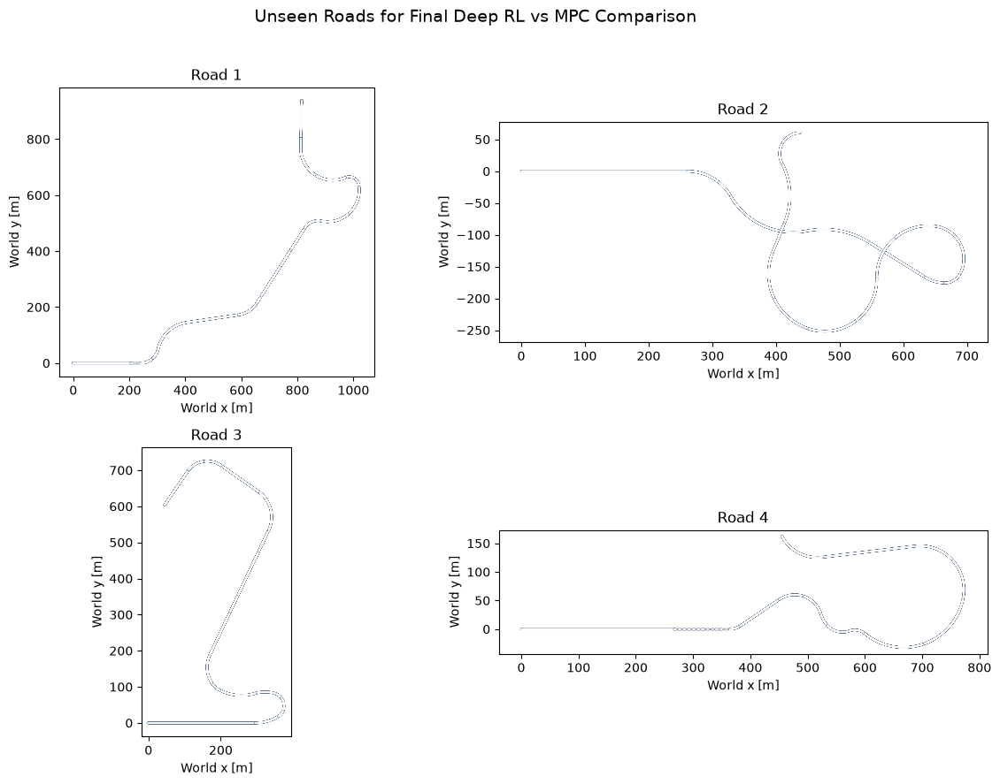

,road,length_m
0,Road 1,1806.359375
1,Road 2,1507.659302
2,Road 3,1556.289307
3,Road 4,1260.737549


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
road_summary = []

for ax, (road_name, road_spec) in zip(axes.flat, COMPARISON_ROADS.items()):
    road = Road(road_spec=road_spec)
    road.plot_road_on_matplotlib_axis(ax)
    ax.set_title(road_name)
    ax.set_xlabel("World x [m]")
    ax.set_ylabel("World y [m]")
    ax.set_aspect("equal", adjustable="box")
    road_summary.append({"road": road_name, "length_m": road.total_length_m})

fig.suptitle("Unseen Roads for Final Deep RL vs MPC Comparison", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()
display(pd.DataFrame(road_summary))

## 3. Final MPC configuration

In [31]:
MPC_OBSERVATION_CONFIG = {
    "body_longitudinal_velocity_mps": {
        "destination": "observation", "scaling_factor": 1.0,
    },
    "front_wheel_steering_angle_rad": {
        "destination": "observation", "scaling_factor": 1.0,
    },
    "lateral_error_from_target_line_m": {
        "destination": "observation", "scaling_factor": 1.0,
    },
    "heading_error_from_target_line_rad": {
        "destination": "observation", "scaling_factor": 1.0,
    },
    "recommended_speed_mps": {
        "destination": "observation", "scaling_factor": 1.0,
    },
    "next_recommended_speed_change": {
        "value_mps": {
            "destination": "observation", "scaling_factor": 1.0,
        },
        "reference_line_distance_m": {
            "destination": "observation", "scaling_factor": 1.0,
        },
    },
}


def build_final_mpc_config(env):
    model = KinematicBicycleMPCModelConfig.from_env(env)

    return AutonomousDrivingSteeringRateMPCConfig.teaching_baseline(
        horizon_steps=30,
        model=model,
        objective=SteeringRateMPCObjectiveConfig(
            speed_state_quadratic_weight=2.0,
            speed_state_linear_weight=0.0,
            lateral_error_state_quadratic_weight=2.0,
            lateral_error_state_linear_weight=0.0,
            heading_error_state_quadratic_weight=0.1,
            heading_error_state_linear_weight=0.0,
            steering_angle_state_quadratic_weight=0.1,
            steering_angle_state_linear_weight=0.0,
            normalized_drive_command_control_quadratic_weight=20.0,
            normalized_drive_command_control_linear_weight=0.0,
            steering_rate_control_quadratic_weight=0.2,
            steering_rate_control_linear_weight=0.0,
        ),
        constraints=SteeringRateMPCConstraintConfig(
            normalized_drive_command_control_lower=-0.5,
            normalized_drive_command_control_upper=0.5,
            normalized_drive_command_control_change_lower_per_step=-0.05,
            normalized_drive_command_control_change_upper_per_step=0.05,
            soft_speed_state_lower_mps=0.0,
            recommended_speed_soft_upper_margin_mps=0.0,
            soft_lateral_error_state_lower_metres=None,
            soft_lateral_error_state_upper_metres=None,
            soft_heading_error_state_lower_radians=None,
            soft_heading_error_state_upper_radians=None,
            soft_state_linear_penalty=20.0,
            soft_state_quadratic_penalty=1.0,
        ),
        solver=MPCSolverConfig(
            verbose=False,
            absolute_tolerance=1e-3,
            relative_tolerance=1e-8,
            polishing=True,
        ),
        fallback=MPCFallbackConfig(
            mode=MPCFallbackMode.HOLD_PREVIOUS_ACTION
        ),
    )


def build_mpc_environment_kwargs(physical_environment_kwargs, road_spec):
    kwargs = copy.deepcopy(physical_environment_kwargs)
    kwargs["road_spec"] = copy.deepcopy(road_spec)
    kwargs["observation_format"] = "dict"
    kwargs["observation_config"] = copy.deepcopy(MPC_OBSERVATION_CONFIG)
    kwargs["ground_truth_mode"] = "operational"
    kwargs["target_line_config"] = {"mode": "reference_line"}
    kwargs["internal_policy_config"] = {
        "lane_keeping": {"enabled": False},
        "cruise_control": {"enabled": False},
        "action_interface": "full",
    }
    return kwargs

## 4. Evaluate final Deep RL and final MPC

In [32]:
def rollout_flag(time_series, key):
    values = np.asarray(time_series.get(key, False))
    return bool(np.any(values)) if values.size else False


comparison_rows = []
comparison_trajectories = {}

with load_model_and_config_for_evaluation(
    FINAL_RL_MODEL_PATH,
    explicit_config=FINAL_RL_CONFIG_PATH,
) as loaded_rl:

    snapshot = loaded_rl.config.to_dict()
    physical_environment_kwargs = copy.deepcopy(
        snapshot["environment"]["public_constructor_template"]
    )
    tire_condition = snapshot["environment"]["postconstruction_settings"][
        "tire_force_condition"
    ]
    rl_policy = RLPolicy(loaded_rl.model)

    for road_index, (road_name, road_spec) in enumerate(COMPARISON_ROADS.items()):
        reset_seed = BASE_RESET_SEED + road_index
        print(f"Evaluating {road_name}...")

        # Deep RL
        rl_kwargs = copy.deepcopy(physical_environment_kwargs)
        rl_kwargs["road_spec"] = copy.deepcopy(road_spec)
        rl_env = gym.make("dreamgym/autonomous_driving_env", **rl_kwargs)
        try:
            rl_env.unwrapped.set_tire_force_condition(tire_condition)
            rl_ts = simulate_policy(
                rl_env,
                N_STEPS,
                rl_policy,
                seed=reset_seed,
            )
        finally:
            rl_env.close()

        # MPC
        mpc_kwargs = build_mpc_environment_kwargs(
            physical_environment_kwargs,
            road_spec,
        )
        mpc_env = gym.make("dreamgym/autonomous_driving_env", **mpc_kwargs)
        try:
            mpc_env.unwrapped.set_tire_force_condition(tire_condition)
            mpc_config = build_final_mpc_config(mpc_env)
            mpc_policy = AutonomousDrivingSteeringRateMPCPolicy.from_env(
                mpc_env,
                mpc_config,
            )
            mpc_history = simulate_mpc_policy(
                mpc_env,
                N_STEPS,
                mpc_policy,
                seed=reset_seed,
                capture_world_predictions=False,
            )
            mpc_ts = mpc_history.simulation_time_series
        finally:
            mpc_env.close()

        # Common metrics
        for policy_name, time_series in (("Deep RL", rl_ts), ("MPC", mpc_ts)):
            row = {
                "road": road_name,
                "road_generation_seed": COMPARISON_ROAD_SEEDS[road_index],
                "reset_seed": reset_seed,
                "policy": policy_name,
                "terminated": rollout_flag(time_series, "terminated"),
                "truncated": rollout_flag(time_series, "truncated"),
            }
            for metric in COMPARISON_METRICS:
                row[metric.name] = float(metric.function(time_series))
            comparison_rows.append(row)

        # Save trajectories for animation without rerunning.
        comparison_trajectories[road_name] = {
            "road_spec": copy.deepcopy(road_spec),
            "reset_seed": reset_seed,
            "Deep RL": copy.deepcopy(rl_ts),
            "MPC": copy.deepcopy(mpc_ts),
        }

print("Evaluation complete.")

Evaluating Road 1...
Evaluating Road 2...
Evaluating Road 3...
Evaluating Road 4...
Evaluation complete.


## 5. Per-road results

In [33]:
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

per_road_path = OUTPUT_ROOT / "per_road_comparison.csv"
comparison_df.to_csv(per_road_path, index=False)
print("Saved:", per_road_path)

,road,road_generation_seed,reset_seed,policy,terminated,truncated,mean_abs_lateral_error_m,mean_abs_speed_error_to_recommended_kph,final_progress_m,fraction_outside_lateral_tolerance,cumulative_overspeed_duration_s,maximum_overspeed_kph,rms_longitudinal_jerk_mps3,rms_steering_request_rate_rad_per_s
0,Road 1,20261221,20261210,Deep RL,True,False,3.3459,33.7333,1074.0679,0.5922,29.60,87.1263,16.2644,1.9253
1,Road 1,20261221,20261210,MPC,True,False,0.0405,1.7832,1806.3594,0.0000,5.55,22.0487,2.6535,0.0426
2,Road 2,20261222,20261211,Deep RL,True,False,4.9348,53.2292,717.9846,0.9540,23.90,80.6908,15.9150,2.2269
3,Road 2,20261222,20261211,MPC,True,False,0.0524,2.2580,1507.6593,0.0000,8.70,44.9034,2.3113,0.0549
4,Road 3,20261223,20261212,Deep RL,True,False,2.5074,29.8127,373.4450,0.9284,2.90,52.8719,3.3177,0.3730
5,Road 3,20261223,20261212,MPC,True,False,0.0401,3.7414,1556.2893,0.0000,8.20,29.2191,2.9961,0.0315
6,Road 4,20261224,20261213,Deep RL,True,False,4.6453,32.5861,1260.7375,0.6560,35.25,79.9088,14.8010,1.8654
7,Road 4,20261224,20261213,MPC,True,False,0.0589,2.0398,1260.7375,0.0031,3.85,40.4885,2.9090,0.0887


Saved: notebook_outputs/final-rl-vs-mpc-comparison/per_road_comparison.csv


## 6. Mean policy comparison

In [34]:
mean_comparison = (
    comparison_df
    .groupby("policy")[METRIC_NAMES]
    .mean()
    .T
)

outcome_counts = (
    comparison_df
    .groupby("policy")[["terminated", "truncated"]]
    .sum()
    .T
    .rename(index={
        "terminated": "terminated_road_count",
        "truncated": "truncated_road_count",
    })
)

mean_comparison = pd.concat([mean_comparison, outcome_counts])

HIGHER_IS_BETTER = {"final_progress_m"}
OUTCOME_TRACKERS = {"terminated_road_count", "truncated_road_count"}
mean_comparison["Better"] = ""

for metric_name in mean_comparison.index:
    rl_value = float(mean_comparison.loc[metric_name, "Deep RL"])
    mpc_value = float(mean_comparison.loc[metric_name, "MPC"])

    if metric_name in OUTCOME_TRACKERS:
        better = "Status only"
    elif np.isclose(rl_value, mpc_value):
        better = "Tie"
    elif metric_name in HIGHER_IS_BETTER:
        better = "Deep RL" if rl_value > mpc_value else "MPC"
    else:
        better = "Deep RL" if rl_value < mpc_value else "MPC"

    mean_comparison.loc[metric_name, "Better"] = better

display(mean_comparison.round(4))

mean_path = OUTPUT_ROOT / "mean_policy_comparison.csv"
mean_comparison.to_csv(mean_path)
print("Saved:", mean_path)

policy,Deep RL,MPC,Better
mean_abs_lateral_error_m,3.8583,0.0480,MPC
mean_abs_speed_error_to_recommended_kph,37.3403,2.4556,MPC
final_progress_m,856.5588,1532.7614,MPC
fraction_outside_lateral_tolerance,0.7826,0.0008,MPC
cumulative_overspeed_duration_s,22.9125,6.5750,MPC
maximum_overspeed_kph,75.1495,34.1649,MPC
rms_longitudinal_jerk_mps3,12.5745,2.7175,MPC
rms_steering_request_rate_rad_per_s,1.5977,0.0544,MPC
terminated_road_count,4.0000,4.0000,Status only
truncated_road_count,0.0000,0.0000,Status only


Saved: notebook_outputs/final-rl-vs-mpc-comparison/mean_policy_comparison.csv


## 7. Clean report table

In [35]:
DISPLAY_NAMES = {
    "final_progress_m": "Final progress [m]",
    "cumulative_overspeed_duration_s": "Overspeed duration [s]",
    "maximum_overspeed_kph": "Maximum overspeed [km/h]",
    "mean_abs_speed_error_to_recommended_kph": "Mean speed error [km/h]",
    "rms_longitudinal_jerk_mps3": "RMS longitudinal jerk [m/s³]",
    "mean_abs_lateral_error_m": "Mean lateral error [m]",
    "fraction_outside_lateral_tolerance": "Fraction outside lateral tolerance",
    "rms_steering_request_rate_rad_per_s": "RMS steering rate [rad/s]",
    "terminated_road_count": "Terminated roads [count]",
    "truncated_road_count": "Truncated roads [count]",
}

report_table = mean_comparison.rename(index=DISPLAY_NAMES)
display(report_table.round(3))

policy,Deep RL,MPC,Better
Mean lateral error [m],3.858,0.048,MPC
Mean speed error [km/h],37.340,2.456,MPC
Final progress [m],856.559,1532.761,MPC
Fraction outside lateral tolerance,0.783,0.001,MPC
Overspeed duration [s],22.912,6.575,MPC
Maximum overspeed [km/h],75.149,34.165,MPC
RMS longitudinal jerk [m/s³],12.575,2.717,MPC
RMS steering rate [rad/s],1.598,0.054,MPC
Terminated roads [count],4.000,4.000,Status only
Truncated roads [count],0.000,0.000,Status only


## 9. Animate both policies on every comparison road

In [36]:
def animate_policy_comparison(
    road_name,
    road_spec,
    rl_ts,
    mpc_ts,
    *,
    dt=0.05,
    frame_step=10,
):
    rl_x = np.asarray(rl_ts["px"], dtype=float)
    rl_y = np.asarray(rl_ts["py"], dtype=float)
    mpc_x = np.asarray(mpc_ts["px"], dtype=float)
    mpc_y = np.asarray(mpc_ts["py"], dtype=float)

    frame_count = max(len(rl_x), len(mpc_x))
    frame_indices = range(0, frame_count, frame_step)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    rl_ax, mpc_ax = axes

    road = Road(road_spec=road_spec)
    road.plot_road_on_matplotlib_axis(rl_ax)
    road.plot_road_on_matplotlib_axis(mpc_ax)

    rl_ax.set_title("Deep RL")
    mpc_ax.set_title("MPC")

    for ax in axes:
        ax.set_xlabel("World x [m]")
        ax.set_ylabel("World y [m]")
        ax.set_aspect("equal", adjustable="box")

    rl_car, = rl_ax.plot([], [], marker="o", markersize=8, linestyle="None")
    mpc_car, = mpc_ax.plot([], [], marker="o", markersize=8, linestyle="None")
    rl_trail, = rl_ax.plot([], [], linewidth=2)
    mpc_trail, = mpc_ax.plot([], [], linewidth=2)
    time_text = fig.text(0.5, 0.02, "", ha="center")

    def update(frame_index):
        rl_index = min(frame_index, len(rl_x) - 1)
        mpc_index = min(frame_index, len(mpc_x) - 1)

        rl_car.set_data([rl_x[rl_index]], [rl_y[rl_index]])
        mpc_car.set_data([mpc_x[mpc_index]], [mpc_y[mpc_index]])
        rl_trail.set_data(rl_x[:rl_index + 1], rl_y[:rl_index + 1])
        mpc_trail.set_data(mpc_x[:mpc_index + 1], mpc_y[:mpc_index + 1])
        time_text.set_text(f"t = {frame_index * dt:.1f} s")

        return rl_car, mpc_car, rl_trail, mpc_trail, time_text

    animation = FuncAnimation(
        fig,
        update,
        frames=frame_indices,
        interval=50,
        blit=False,
        repeat=True,
    )

    fig.suptitle(f"Deep RL vs MPC: {road_name}", fontsize=14)
    plt.tight_layout(rect=(0, 0.04, 1, 0.95))
    return fig, animation

In [37]:
FRAME_STEP = 10
ALL_COMPARISON_ANIMATIONS = {}

for road_name, data in comparison_trajectories.items():
    print("\n" + "=" * 60)
    print(road_name, "reset seed =", data["reset_seed"])

    fig, animation = animate_policy_comparison(
        road_name=road_name,
        road_spec=data["road_spec"],
        rl_ts=data["Deep RL"],
        mpc_ts=data["MPC"],
        dt=DT,
        frame_step=FRAME_STEP,
    )

    ALL_COMPARISON_ANIMATIONS[road_name] = animation
    display(HTML(animation.to_jshtml(default_mode="loop")))
    plt.close(fig)


Road 1 reset seed = 20261210


Animation size has reached 20992637 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.



Road 2 reset seed = 20261211


Animation size has reached 21002100 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.



Road 3 reset seed = 20261212


Animation size has reached 20987734 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.



Road 4 reset seed = 20261213


Animation size has reached 20998596 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
